# RAG and Agentic RAG for financial questions over SEC filings: an ablation study of five architectures with validated *ground truth*

**NLP final project — MSc in Artificial Intelligence (USFQ)**
**Author:** Fernando Soto · **Course topic:** 3. RAG or Agentic RAG with LangChain and LangGraph

This notebook compares five RAG systems of increasing complexity, from a lexical baseline (BM25) to a LangGraph agent with tools. The questions are financial and are answered over 10-K and 10-Q filings of 10 Nasdaq-100 companies.

| Section | Content |
|---|---|
| 1 | Problem |
| 2 | Data (SEC corpus) |
| 3 | Systems: baseline and proposed solution |
| 4 | Evaluation set |
| 5 | Evaluation with RAGAS (same measure for the 5 systems) |
| 6 | Cost comparison (tokens, LLM calls, latency, USD) |
| 7 | Behavior on adversarial questions |
| 8 | Demo: one question, five systems |
| 9 | A question with no answer in the corpus |
| 10 | Conclusions and limits |

In [1]:
import json
import re
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
DATA = ROOT / "data"
EVAL = DATA / "evaluation"

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

SYSTEMS = {
    1: "S1 BM25",
    2: "S2 Vector",
    3: "S3 Hybrid",
    4: "S4 Hybrid+Graph",
    5: "S5 Agentic",
}
COLORS = ["#9aa5b1", "#7b8794", "#52606d", "#3e7cb1", "#d9822b"]

## 1. Problem

An analyst researching listed companies needs answers that are **numerical, traceable and tied to the right fiscal period**: revenue, margins, ratios and comparisons across years or companies. That information is scattered across long documents (a 10-K has more than 100 pages) and mixes tables, narrative text and fiscal periods that do not match the calendar year.

**Research question:** how much does each component of a RAG system (lexical search, semantic search, hybrid fusion, knowledge graph and an agent with tools) contribute to answer quality, and at what cost?

To answer it we run an **ablation study**: each system adds one component on top of the previous one, and all of them are evaluated with the same questions, the same metric (RAGAS) and the same cost measure.

## 2. Data

**Source:** SEC EDGAR, with 10-K (annual) and 10-Q (quarterly) filings downloaded directly from the SEC.
**Universe:** the 10 largest companies by weight in the Nasdaq-100.
**Period:** fiscal years 2020–2026.

In [2]:
universe = pd.read_csv(DATA / "universe.csv")
universe[["ticker", "company_name", "rank", "weight_pct"]]

,ticker,company_name,rank,weight_pct
0,NVDA,NVIDIA Corporation,1,8.66
1,AAPL,Apple Inc.,2,7.80
2,MSFT,Microsoft Corporation,3,6.31
3,GOOGL,Alphabet Inc.,4,6.17
4,MU,Micron Technology Inc.,5,4.62
5,AMZN,Amazon.com Inc.,6,4.31
6,AMD,Advanced Micro Devices Inc.,7,4.23
7,META,Meta Platforms Inc.,8,3.53
8,TSLA,Tesla Inc.,9,2.92
9,AVGO,Broadcom Inc.,10,2.65


In [3]:
chunks = pd.read_json(DATA / "chunks" / "chunks.jsonl", lines=True)

corpus_stats = pd.Series({
    "Documents (10-K and 10-Q)": chunks["document_id"].nunique(),
    "Chunks": len(chunks),
    "Total words": int(chunks["word_count"].sum()),
    "Words per chunk (median)": int(chunks["word_count"].median()),
    "Chunks without company_id": int(chunks["company_id"].isna().sum()),
}, name="value")
corpus_stats.to_frame()

,value
Documents (10-K and 10-Q),206
Chunks,6536
Total words,5981174
Words per chunk (median),319
Chunks without company_id,1220


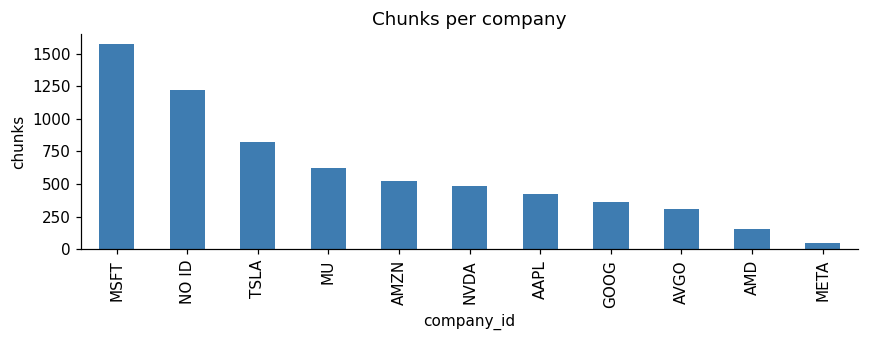

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.2))
chunks["company_id"].fillna("NO ID").value_counts().plot.bar(ax=ax, color="#3e7cb1")
ax.set_title("Chunks per company")
ax.set_ylabel("chunks")
plt.tight_layout()
plt.show()

**Preprocessing:**
1. HTML parsing → text normalized by section (Item 1, Item 7, etc.), keeping metadata: company, form type and period end date.
2. Chunking with a paragraph-aware splitter with overlap (`src/retrieval/chunker.py`). Each chunk carries a `[Company | Document | Section]` header so the LLM can cite the source.
3. BGE-M3 embeddings (1024 dimensions) generated on an H200 GPU (~5 min for the whole corpus).
4. Indexes: BM25 (Okapi) and FAISS `IndexFlatIP` (cosine similarity).
5. Knowledge graph: entities and relations extracted with an LLM (NetworkX, 943 nodes and 1,477 edges).

Note: 1,220 chunks have no `company_id` in their metadata, although the text header does identify the company. This affects company filters, but not search.

## 3. Systems: baseline and proposed solution

| System | Role | Retrieval | Chunks sent to the LLM | Calls |
|---|---|---|---|---|
| **S1 BM25** | **Baseline** | BM25 (Okapi) | 8 full chunks | 1 |
| **S2 Vector** | Ablation | BGE-M3 + FAISS | 8 full chunks | 1 |
| **S3 Hybrid** | Ablation | S1 + S2 fused with RRF (k=60) | 8 full chunks | 1 |
| **S4 Hybrid+Graph** | Ablation | S3 + KG subgraph (5 entities, 5 relations) | 8 chunks cut to 1000 characters + KG | 1 |
| **S5 Agentic** | **Proposed solution** | ReAct agent in LangGraph with 3 tools: `search` (hybrid + KG), `get_financial_facts` (XBRL) and `calculator` | 15 previews of 800 characters per search | 1–4 |

**Use of each LLM:** gpt-4o-mini (temperature 0) generates the answers of S1–S4 and extracted the entities and relations of the knowledge graph. GLM-5.3-Flash, served on a self-hosted endpoint, generates the answers of S5 and acts as the RAGAS judge.

**Baseline:** S1, a single-step lexical RAG.
**Solution:** S5, a multi-step agent that decides which tool to use, can search several times, compute, and query structured XBRL data.

### Agent graph (S5)

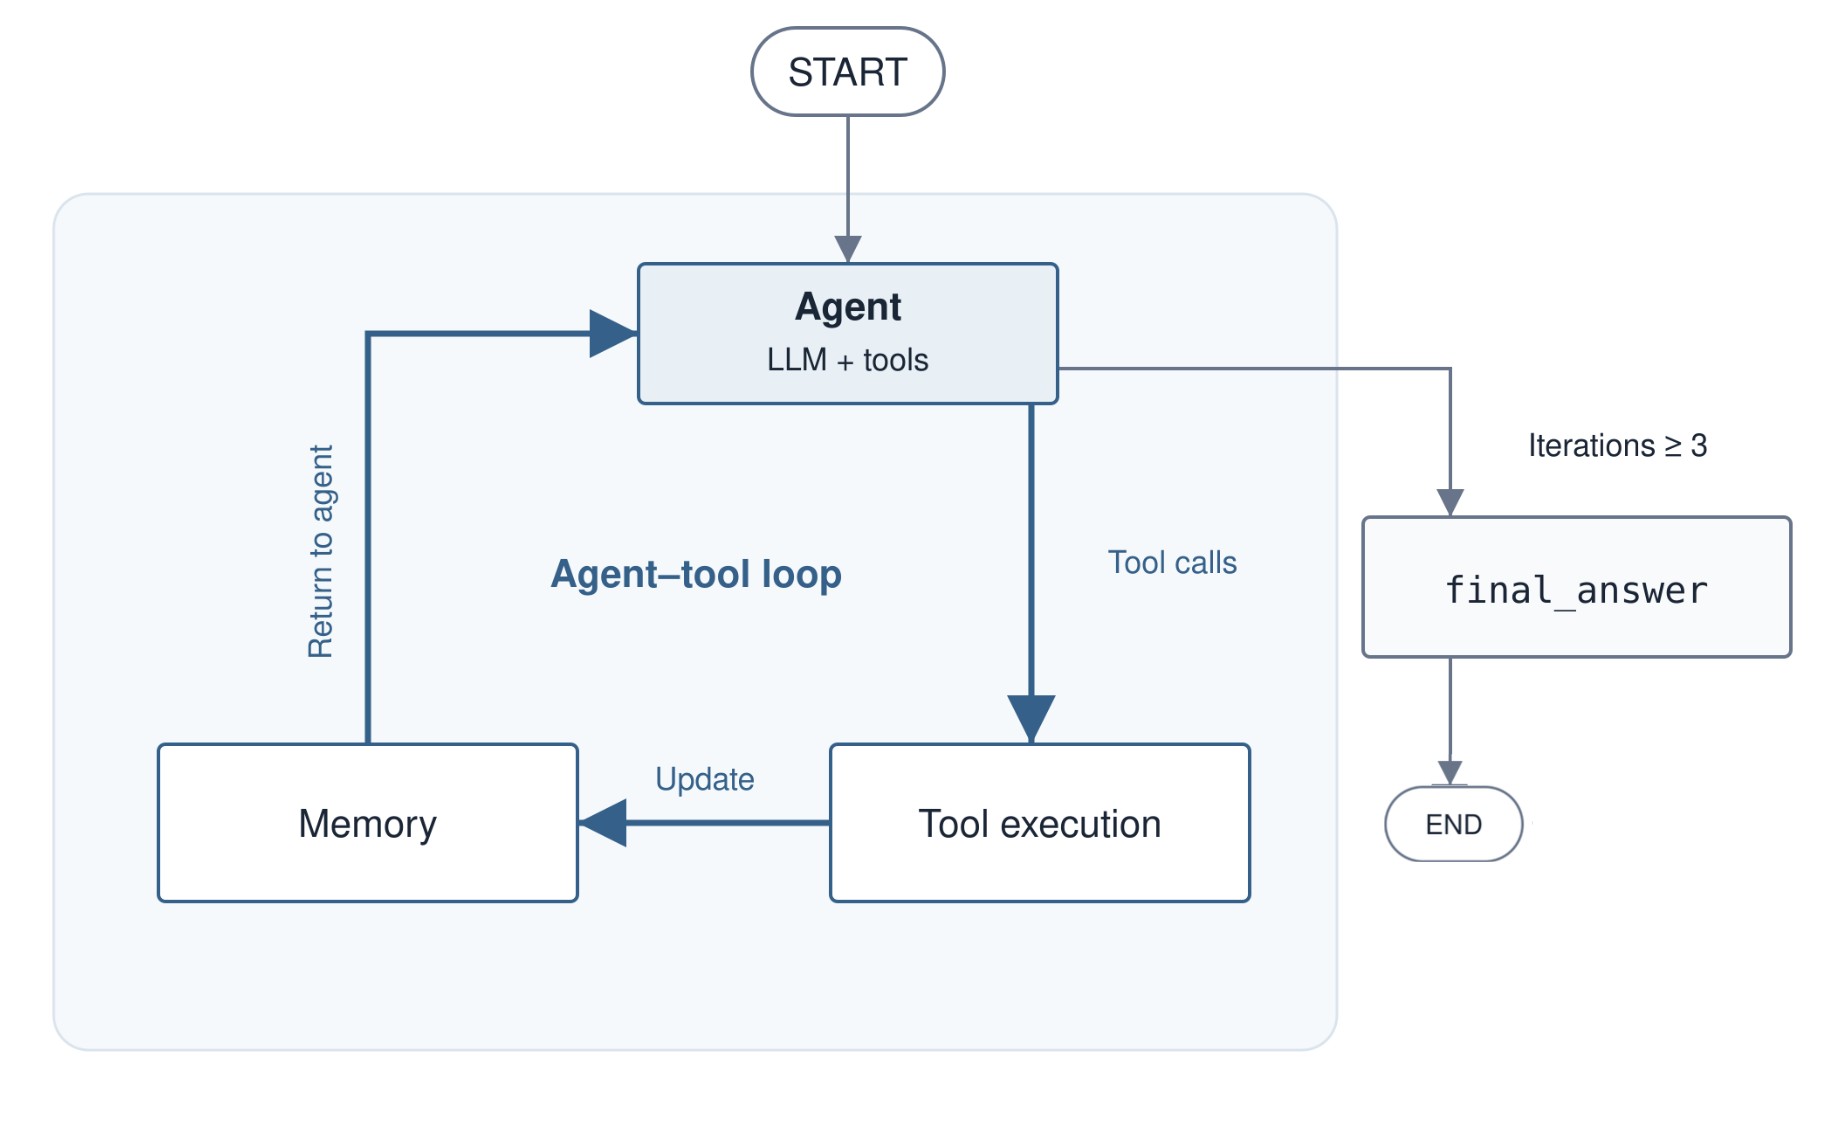




The `memory` node records the tools that failed and the searches already done, and injects them into the agent at every iteration so it does not repeat actions. `MAX_ITERATIONS = 3` bounds the cost.

### Solution code (S5)

The following cells show the actual agent code, read directly from `src/`. Nothing is imported: this way the notebook runs without an LLM server or loaded models.

In [5]:
def show_source(path, start, end=None):
    """Prints the fragment of a source file between two markers."""
    src = (ROOT / path).read_text()
    i = src.index(start)
    j = src.index(end, i + len(start)) if end else len(src)
    print(f"# --- {path} ---\n")
    print(src[i:j].rstrip())

**1. The agent's 3 tools** (`src/tools/agent_tools.py`). Each function carries LangChain's `@tool` decorator, and its docstring is the description the LLM reads to decide when to use it. The `TOOLS` list is the single source of truth: both `bind_tools()` and `ToolNode()` use it.

In [6]:
show_source("src/tools/agent_tools.py", "@tool\ndef search", "# ====")
show_source("src/tools/agent_tools.py", "TOOLS = [")

# --- src/tools/agent_tools.py ---

@tool
def search(query: str) -> str:
    """Search SEC documents using hybrid retrieval + knowledge graph.

    Use this for:
    - Finding financial data in 10-K/10-Q documents
    - Getting context about company performance
    - Exploring detailed financial information

    Args:
        query: Natural language search query about financial data

    Returns:
        Relevant document excerpts with metadata
    """
    return _search_docs(query, top_k=15)


@tool
def calculator(expression: str) -> str:
    """Evaluate mathematical expressions safely.

    Use this for:
    - Growth rates: ((new - old) / old) * 100
    - Ratios and percentages
    - Basic arithmetic: +, -, *, /, **

    Args:
        expression: Math expression like "((383.3 - 394.3) / 394.3) * 100"

    Returns:
        Calculated result or error message
    """
    calc = Calculate()
    result = calc.calculate(expression)

    if result['error']:
        return f"Error: {result['

**2. Graph construction with LangGraph** (`src/systems/system5_agentic.py`). The graph has 4 nodes (`agent`, `tools`, `memory`, `final_answer`), a conditional routing after the agent and a `tools → memory → agent` loop.

In [7]:
show_source("src/systems/system5_agentic.py", "def create_agent_graph", "# ====")

# --- src/systems/system5_agentic.py ---

def create_agent_graph():
    """Creates the LangGraph agent with memory."""

    # Load .env
    from dotenv import load_dotenv
    project_root = Path(__file__).parent.parent.parent
    load_dotenv(project_root / ".env")

    # Pre-load BGE-M3
    print("  Pre-loading BGE-M3...")
    from FlagEmbedding import BGEM3FlagModel
    _ = BGEM3FlagModel("BAAI/bge-m3", use_fp16=False)
    print("    BGE-M3 loaded")

    workflow = StateGraph(AgentState)

    # Nodes
    workflow.add_node("agent", call_model)
    workflow.add_node("tools", ToolNode(TOOLS))  # TOOLS from agent_tools.py
    workflow.add_node("memory", update_memory)
    workflow.add_node("final_answer", generate_final_answer)  # forces a final answer

    # Entry
    workflow.set_entry_point("agent")

    # Routing
    workflow.add_conditional_edges(
        "agent",
        should_continue,
        {
            "tools": "tools",
            "final_answer": "final_answer",  # when MAX_

**3. Agent node and routing.** `call_model` injects the memory (failed tools and searches done) at every iteration and calls the LLM with the bound tools. `should_continue` decides whether to run tools, finish, or force the final answer when `MAX_ITERATIONS = 3` is reached.

In [8]:
show_source("src/systems/system5_agentic.py", "def should_continue", "def update_memory")

# --- src/systems/system5_agentic.py ---

def should_continue(state: AgentState) -> str:
    """Decides whether to continue or stop."""
    MAX_ITERATIONS = 3

    messages = state["messages"]
    last_message = messages[-1]

    # Safety: force a final answer after max iterations
    if state.get("iterations", 0) >= MAX_ITERATIONS:
        return "final_answer"

    # Tool calls requested and still under the limit: continue
    if hasattr(last_message, "tool_calls") and last_message.tool_calls:
        if state.get("iterations", 0) < MAX_ITERATIONS:
            return "tools"
        return "final_answer"

    # Otherwise end
    return "end"


def call_model(state: AgentState) -> Dict:
    """Calls the LLM with the memory context."""

    messages = list(state["messages"])

    # Inject memory on every iteration
    failed_tools = state.get("failed_tools", [])
    search_count = len(state.get("search_queries_used", []))
    iteration = state.get("iterations", 0)

    if iteration > 0

## 4. Evaluation set

The evaluation uses **35 questions of seven types**. Five types have a concrete expected answer: single figures, comparisons across companies, calculations over several figures, multi-hop questions that combine several sections of a filing, and explanations of a company's strategy. The other two are adversarial and their correct answer is not a number:
- **Ambiguity:** the year, period or metric type is missing; the system is expected to ask for clarification.
- **Knowledge gap:** the information is not in the 10-K/10-Q filings (earnings call transcripts, current market prices, executive compensation from the proxy statement); the system is expected to admit it.

In [9]:
qfinal = json.load(open(EVAL / "questions_validated.json"))
questions = pd.DataFrame(qfinal["questions"])

TYPE_NAMES = {
    "numeric": "Numeric", "comparative": "Comparative", "calculation": "Calculation",
    "multihop": "Multi-hop", "explanatory": "Explanatory",
    "ambiguity_detection": "Ambiguity", "knowledge_gap": "Knowledge gap",
}
# Q59 (Amazon revenue in Q1 2024) has an answer in the corpus: it is a numeric question
questions["type"] = questions["category"].map(TYPE_NAMES)
questions.loc[questions["id"] == 59, "type"] = "Numeric"

EXAMPLES = {"Numeric": 1, "Comparative": 10, "Calculation": 17, "Multi-hop": 21,
            "Explanatory": 25, "Ambiguity": 53, "Knowledge gap": 57}
by_id = questions.set_index("id")["question"]

dist = (questions["type"].value_counts()
        .reindex(list(TYPE_NAMES.values()))
        .rename("questions").to_frame())
dist["example"] = [by_id[EXAMPLES[t]] for t in dist.index]
dist.loc["Total"] = [dist["questions"].sum(), ""]
dist

,questions,example
type,,
Numeric,7,What was Apple's total revenue in fiscal year 2023?
Comparative,4,"Between Google and Amazon, which had better operating margin in 2023?"
Calculation,5,What was Amazon's operating cash flow as a percentage of revenue in 2023?
Multi-hop,6,How did NVIDIA's acquisition strategy relate to their AI business growth in 2023?
Explanatory,5,Why did Apple's revenue decline in fiscal 2023 despite strong brand performance?
Ambiguity,5,How much did Tesla spend on capital expenditures?
Knowledge gap,3,What is the current stock price of Tesla?
Total,35,


**Validation of the expected answers.** They were validated against the corpus by LLM judges working blindly, without knowing each other's verdicts. GPT-6 Astra validated the 35 questions. Claude Opus 5.5 independently reviewed 16 of them (the 6 with figures that needed extra verification and the 10 adversarial ones), agreeing on 15 of 16. In the only disagreement, the answer with evidence in the corpus was kept.

## 5. Evaluation with RAGAS (same measure for the 5 systems)

Three RAGAS metrics were used, with BGE-M3 for the embeddings:

- **Faithfulness:** is the answer supported by the retrieved contexts? It does not depend on the ground truth.
- **Context recall:** do the retrieved contexts contain the information of the expected answer? It measures retrieval.
- **Answer correctness:** does the answer match the expected one? It combines factual and semantic similarity, and is the main accuracy measure.

In [10]:
ragas = json.load(open(EVAL / "ragas_scores.json"))

rows = []
for key, s in ragas["systems"].items():
    m = s["metrics"]
    rows.append({
        "system": SYSTEMS[s["system_id"]],
        "faithfulness": m["faithfulness"]["score"],
        "context_recall": m["context_recall"]["score"],
        "answer_correctness": m["answer_correctness"]["score"],
        "n evaluated (AC)": f'{m["answer_correctness"]["successful_evals"]}/35',
    })
ragas_df = pd.DataFrame(rows).set_index("system")
ragas_df.style.format({c: "{:.1%}" for c in ["faithfulness", "context_recall", "answer_correctness"]}) \
    .highlight_max(subset=["faithfulness", "context_recall", "answer_correctness"], color="#d4e6f7")

,faithfulness,context_recall,answer_correctness,n evaluated (AC)
system,,,,
S1 BM25,90.1%,32.2%,33.4%,31/35
S2 Vector,93.0%,34.6%,37.3%,32/35
S3 Hybrid,86.3%,39.8%,29.5%,32/35
S4 Hybrid+Graph,76.2%,45.8%,31.2%,34/35
S5 Agentic,42.9%,19.9%,44.1%,32/35


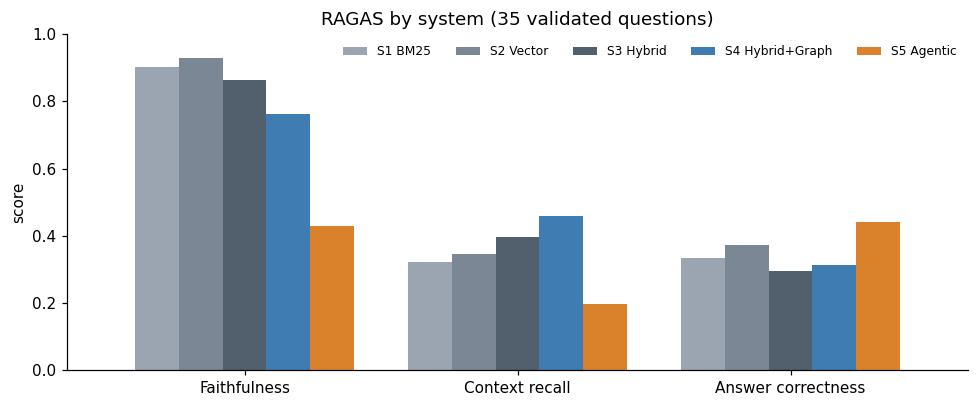

In [11]:
metrics = ["faithfulness", "context_recall", "answer_correctness"]
fig, ax = plt.subplots(figsize=(9, 3.8))
ragas_df[metrics].T.plot.bar(ax=ax, color=COLORS, width=0.8)
ax.set_ylim(0, 1)
ax.set_ylabel("score")
ax.set_title("RAGAS by system (35 validated questions)")
ax.set_xticklabels(["Faithfulness", "Context recall", "Answer correctness"], rotation=0)
ax.legend(ncol=5, fontsize=8, loc="upper right", frameon=False)
plt.tight_layout()
plt.show()

### Ablation: contribution of each component

Difference in percentage points when moving from one system to the next.

In [12]:
steps = [
    ("BM25 → Vector", 1, 2),
    ("Vector → Hybrid (+BM25, RRF)", 2, 3),
    ("Hybrid → +Knowledge Graph", 3, 4),
    ("+KG → Agent (LangGraph + tools)", 4, 5),
    ("Baseline (BM25) → Solution (Agent)", 1, 5),
]
delta = pd.DataFrame([
    {"step": name, **{m: (ragas_df.loc[SYSTEMS[b], m] - ragas_df.loc[SYSTEMS[a], m]) * 100 for m in metrics}}
    for name, a, b in steps
]).set_index("step")
delta.style.format("{:+.1f} pp").background_gradient(cmap="RdYlGn", vmin=-50, vmax=50)

,faithfulness,context_recall,answer_correctness
step,,,
BM25 → Vector,+2.9 pp,+2.4 pp,+3.9 pp
"Vector → Hybrid (+BM25, RRF)",-6.8 pp,+5.2 pp,-7.8 pp
Hybrid → +Knowledge Graph,-10.1 pp,+6.0 pp,+1.7 pp
+KG → Agent (LangGraph + tools),-33.3 pp,-25.9 pp,+12.9 pp
Baseline (BM25) → Solution (Agent),-47.2 pp,-12.3 pp,+10.7 pp


## 6. Cost comparison

Cost per query over the **31 questions that all five systems answered**: tokens (computed over the prompts sent to the LLM), LLM calls, latency and USD at the gpt-4o-mini price ($0.15 per million input tokens and $0.60 per million output tokens).

The total project spend on gpt-4o-mini was approximately **USD 6**, including the knowledge graph extraction (USD 0.22). S5 and the RAGAS judge ran on the self-hosted GLM endpoint at no monetary cost; for comparison, their token usage is valued at the same gpt-4o-mini price.

In [13]:
costs = json.load(open(EVAL / "cost_estimates.json"))
cost_df = pd.DataFrame(costs["summary_common_set"]).T
cost_df = cost_df[["mean_input_tokens", "mean_output_tokens", "mean_total_tokens",
                   "mean_llm_calls", "mean_latency_s", "cost_per_1000_queries_usd"]]
cost_df.columns = ["input tokens", "output tokens", "total tokens", "LLM calls", "latency (s)", "USD / 1000 queries"]
print(f'Common set: {len(costs["common_question_ids"])} questions answered by all 5 systems')
cost_df

Common set: 31 questions answered by all 5 systems


,input tokens,output tokens,total tokens,LLM calls,latency (s),USD / 1000 queries
S1 BM25,17036.0,85.0,17121.0,1.00,3.54,2.61
S2 Vector,14975.0,89.0,15064.0,1.00,2.61,2.30
S3 Hybrid,16373.0,90.0,16463.0,1.00,3.23,2.51
S4 Hybrid+Graph,2038.0,350.0,2388.0,1.00,8.58,0.52
S5 Agentic,15809.0,442.0,16251.0,3.84,8.32,2.64


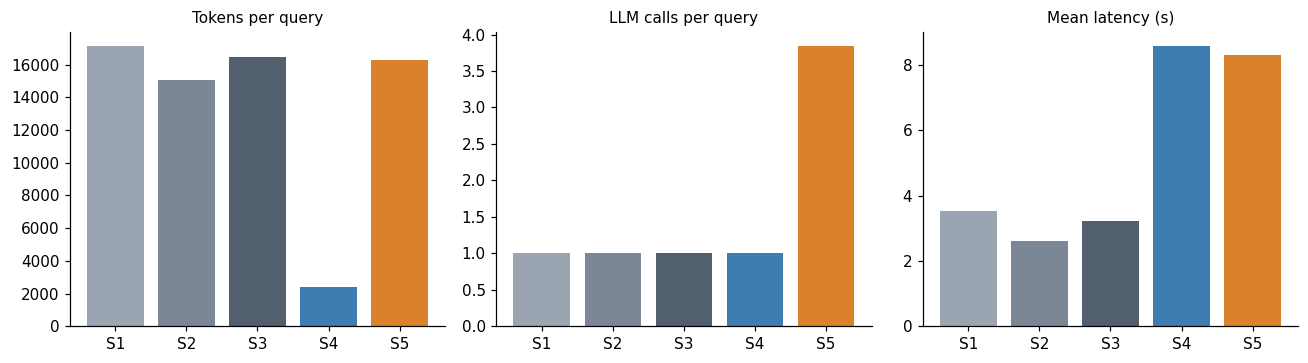

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, col, title in zip(axes,
                          ["total tokens", "LLM calls", "latency (s)"],
                          ["Tokens per query", "LLM calls per query", "Mean latency (s)"]):
    ax.bar(range(5), cost_df[col].astype(float), color=COLORS)
    ax.set_xticks(range(5), [s.split()[0] for s in cost_df.index])
    ax.set_title(title, fontsize=10)
plt.tight_layout()
plt.show()

### Quality vs. cost

Answer correctness (quality) against tokens per query (cost), over the same questions for the 5 systems.

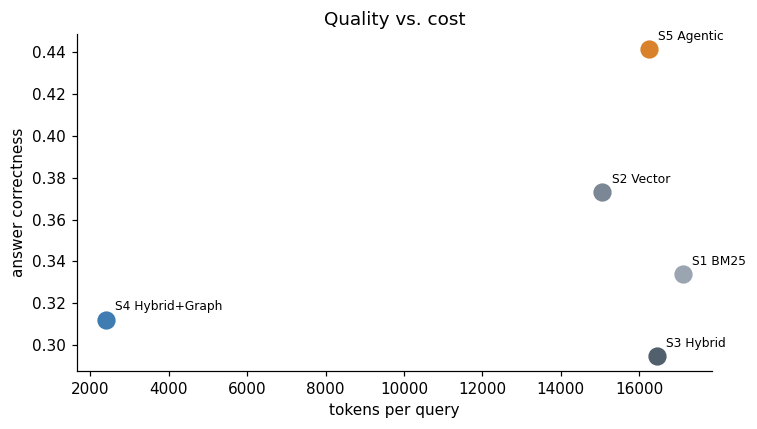

,answer_correctness,faithfulness,total tokens,LLM calls,latency (s),USD / 1000 queries,tokens per AC point
system,,,,,,,
S1 BM25,33.4%,90.1%,17121.000000,1.000000,3.540000,2.610000,513.000000
S2 Vector,37.3%,93.0%,15064.000000,1.000000,2.610000,2.300000,404.000000
S3 Hybrid,29.5%,86.3%,16463.000000,1.000000,3.230000,2.510000,558.000000
S4 Hybrid+Graph,31.2%,76.2%,2388.000000,1.000000,8.580000,0.520000,77.000000
S5 Agentic,44.1%,42.9%,16251.000000,3.840000,8.320000,2.640000,368.000000


In [15]:
tradeoff = ragas_df[["answer_correctness", "faithfulness"]].join(cost_df[["total tokens", "LLM calls", "latency (s)", "USD / 1000 queries"]])
tradeoff["tokens per AC point"] = (tradeoff["total tokens"].astype(float) / (tradeoff["answer_correctness"] * 100)).round(0)

fig, ax = plt.subplots(figsize=(7, 4))
for (name, r), c in zip(tradeoff.iterrows(), COLORS):
    ax.scatter(r["total tokens"], r["answer_correctness"], s=120, color=c)
    ax.annotate(name, (r["total tokens"], r["answer_correctness"]), textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.set_xlabel("tokens per query")
ax.set_ylabel("answer correctness")
ax.set_title("Quality vs. cost")
plt.tight_layout()
plt.show()

tradeoff.style.format({"answer_correctness": "{:.1%}", "faithfulness": "{:.1%}"})

### Queries that exceeded the context window

In [16]:
per_q = pd.read_csv(EVAL / "cost_estimates_per_question.csv")
per_q[per_q["context_overflow"]][["system", "question_id", "category", "input_tokens", "answered"]]

,system,question_id,category,input_tokens,answered
13,S1 BM25,17,calculation,189333,False
22,S1 BM25,27,explanatory,147803,False
28,S1 BM25,54,ambiguity_detection,150629,False


**Queries rejected for size (S1):** BM25 rewards long chunks with many repetitions of the query terms. In Q17, Q27 and Q54 it retrieved whole sections that the chunker did not split (for example, the entire Item 8 of Amazon's 10-K, with more than 100,000 characters). The prompt exceeded the 128k-token window and the API rejected the query. It is a **segmentation and retrieval** failure, not an LLM failure.

## 7. Behavior on adversarial questions

There are 8 adversarial questions whose correct answer **is not a number**:
- **Knowledge gap (Q56–58):** the information is not in the 10-K/10-Q filings. The system is expected to admit it does not have it.
- **Ambiguity (Q51–55):** the year, metric type or period is missing. The system is expected to ask for clarification or state its assumption.

Each answer was classified manually by reading the full text.

In [17]:
VALID_IDS = set(questions["id"])

def load_answers():
    rows = []
    for line in open(EVAL / "results_60q.jsonl"):
        r = json.loads(line)
        if r["system_id"] in (1, 2, 3) and r["question_id"] in VALID_IDS:
            rows.append(r)
    for f in ["results_s4.jsonl", "results_s5.jsonl"]:
        rows += [json.loads(l) for l in open(EVAL / f)]
    df = pd.DataFrame(rows)[["system_id", "question_id", "category", "question", "answer", "expected_answer", "time_seconds"]]
    df["system"] = df["system_id"].map(SYSTEMS)
    return df

answers = load_answers()

# Manual classification of the 40 adversarial answers (8 questions × 5 systems)
GAP = "Admits it lacks the information"
LABELS = {
    # Knowledge gap: all 5 systems admit it in the 3 questions
    56: [GAP] * 5,
    57: [GAP] * 5,
    58: [GAP] * 5,
    # Ambiguity:              S1                           S2                           S3                           S4                           S5
    51: ["Assumes an interpretation","Lists periods",            "Assumes an interpretation","Abstains",                 "Assumes an interpretation"],
    52: ["Abstains",                 "Abstains",                 "Abstains",                 "Abstains",                 "Explains the ambiguity"],
    53: ["Assumes an interpretation","Lists periods",            "Assumes an interpretation","Lists periods",            "Assumes an interpretation"],
    54: ["No answer",                "Abstains",                 "Abstains",                 "Abstains",                 "Abstains"],
    55: ["Assumes an interpretation","Assumes an interpretation","Assumes an interpretation","Assumes an interpretation","Assumes an interpretation"],
}

adv = pd.DataFrame([
    {"question": q, "type": "Knowledge gap" if q >= 56 else "Ambiguity", "system": SYSTEMS[s + 1], "behavior": label}
    for q, labels in LABELS.items() for s, label in enumerate(labels)
])

print("Knowledge gap (3 questions):")
display(pd.crosstab(adv[adv["type"] == "Knowledge gap"]["system"], adv["behavior"]))
print("\nAmbiguity (5 questions):")
pd.crosstab(adv[adv["type"] == "Ambiguity"]["system"], adv["behavior"])

Knowledge gap (3 questions):


behavior,Admits it lacks the information
system,
S1 BM25,3
S2 Vector,3
S3 Hybrid,3
S4 Hybrid+Graph,3
S5 Agentic,3



Ambiguity (5 questions):


behavior,Abstains,Assumes an interpretation,Explains the ambiguity,Lists periods,No answer
system,,,,,
S1 BM25,1,3,0,0,1
S2 Vector,2,1,0,2,0
S3 Hybrid,2,3,0,0,0
S4 Hybrid+Graph,3,1,0,1,0
S5 Agentic,1,3,1,0,0


**Result:**
- **Knowledge gap:** all five systems admit that the information is not in the documents in the 3 questions. None invents a figure.
- **Ambiguity:** no system asks for clarification. Faced with a question without a defined period, they abstain, assume an interpretation without saying so, or list several periods. Only S5, in the question about Microsoft's Q4 profit, explains the ambiguity: Microsoft's fiscal year ends in June, so "Q4" does not refer to the fourth quarter of the calendar year.

## 8. Demo: one question, five systems

How each system answers the same question. For each one we show which companies the retrieved documents belong to, how many tool calls it made, how long it took and what it answered.

In [18]:
from collections import Counter


def load_runs():
    """Answers and retrieved documents of the 5 systems over the 35 questions."""
    rows = []
    for line in open(EVAL / "results_60q.jsonl"):
        r = json.loads(line)
        if r["system_id"] in (1, 2, 3) and r["question_id"] in VALID_IDS:
            rows.append(r)
    for f in ["results_s4.jsonl", "results_s5.jsonl"]:
        rows += [json.loads(l) for l in open(EVAL / f)]
    return rows

runs = load_runs()
SOURCE_S14 = re.compile(r"\[Company: (\w+) \| Document: (\S+) (\S+)")
SOURCE_S5 = re.compile(r"^\[\d+\] (\w+) (\S+) \((\S+)\)", re.M)


def sources(run):
    """Retrieved documents counted per company (per search for S5)."""
    pattern = SOURCE_S5 if run["system_id"] == 5 else SOURCE_S14
    contexts = run.get("retrieved_contexts") or []
    count = lambda ctxs: ", ".join(f"{c} ×{n}" for c, n in Counter(m[0] for ctx in ctxs for m in pattern.findall(ctx)).most_common())
    if run["system_id"] == 5:
        return " | ".join(f"search {k}: {count([ctx])}" for k, ctx in enumerate(contexts, 1))
    return count(contexts)


def demo(qid, max_chars=500):
    q = questions.set_index("id").loc[qid]
    print(f"QUESTION:  {q['question']}")
    print(f"EXPECTED:  {q['expected_answer']}\n")
    for run in sorted((r for r in runs if r["question_id"] == qid), key=lambda r: r["system_id"]):
        tools = f" · {run.get('tool_calls', 0)} tool calls" if run["system_id"] == 5 else ""
        print("─" * 100)
        print(f"{SYSTEMS[run['system_id']]}  ·  {run['time_seconds']:.1f} s{tools}")
        print(f"Retrieved: {sources(run) or '—'}")
        answer = (run["answer"] or "NO ANSWER").strip()
        print(f"Answer:    {answer[:max_chars]}{'…' if len(answer) > max_chars else ''}\n")


demo(4)

QUESTION:  What was Amazon's operating income in Q4 2023?
EXPECTED:  $13.2 billion

────────────────────────────────────────────────────────────────────────────────────────────────────
S1 BM25  ·  3.7 s
Retrieved: AMZN ×8
Answer:    Amazon's operating income in Q4 2023 was $36.9 billion [Document 3].

────────────────────────────────────────────────────────────────────────────────────────────────────
S2 Vector  ·  2.9 s
Retrieved: AMZN ×8
Answer:    The documents do not provide specific information regarding Amazon's operating income for Q4 2023. Therefore, I cannot provide that information.

────────────────────────────────────────────────────────────────────────────────────────────────────
S3 Hybrid  ·  3.3 s
Retrieved: AMZN ×8
Answer:    Amazon's operating income for Q4 2023 was $36.9 billion [Document 7].

────────────────────────────────────────────────────────────────────────────────────────────────────
S4 Hybrid+Graph  ·  7.6 s
Retrieved: AMZN ×8
Answer:    **I don't have enough

**What the demo shows (Q4, Amazon operating income in the fourth quarter of 2023):**

| System | Answer | Result |
|---|---|---|
| S1 BM25 | $36.9B | Incorrect. It is the operating income of the **whole year** 2023; it confuses the quarter with the year |
| S2 Vector | Says the documents do not provide the figure | Abstains |
| S3 Hybrid | $36.9B | Incorrect. Same period error as S1 |
| S4 Hybrid+Graph | "I don't have enough information" | Abstains |
| S5 Agentic | $13.2B | Correct |

The question shows the typical problem of financial filings: the 10-K has the annual figure and the quarterly figure in similar tables. Single-step systems take the first figure they find; the agent searches again when the first search does not settle the period.

**Counterexample: the agent does not always win.** In the question about Meta's R&D spending (Q6), only S2 finds the correct figure, and the agent answers that it does not have the information:

In [19]:
demo(6, max_chars=300)

QUESTION:  How much did Meta spend on research and development in 2023?
EXPECTED:  $38.5 billion

────────────────────────────────────────────────────────────────────────────────────────────────────
S1 BM25  ·  2.4 s
Retrieved: META ×6, MSFT ×2
Answer:    The documents do not provide specific information regarding Meta's research and development spending for the year 2023. Therefore, I cannot provide an answer to that question.

────────────────────────────────────────────────────────────────────────────────────────────────────
S2 Vector  ·  1.6 s
Retrieved: MSFT ×6, META ×2
Answer:    Meta spent $38.48 billion on research and development in 2023 [Document 7].

────────────────────────────────────────────────────────────────────────────────────────────────────
S3 Hybrid  ·  1.5 s
Retrieved: META ×5, MSFT ×2, None ×1
Answer:    The documents provided do not contain information regarding Meta's research and development expenditures for 2023. Therefore, I cannot provide an answer to that 

## 9. A question with no answer in the corpus

The information this question asks for does not exist in any 10-K or 10-Q: the filings are historical and published once per quarter, so they cannot contain a *current* stock price. The correct answer is to admit it.

In [20]:
demo(57)

QUESTION:  What is the current stock price of Tesla?
EXPECTED:  Information not available - 10-Ks don't contain current stock prices

────────────────────────────────────────────────────────────────────────────────────────────────────
S1 BM25  ·  1.1 s
Retrieved: TSLA ×8
Answer:    The current stock price of Tesla is not provided in the documents.

────────────────────────────────────────────────────────────────────────────────────────────────────
S2 Vector  ·  0.9 s
Retrieved: TSLA ×6, None ×2
Answer:    The current stock price of Tesla is not provided in the documents.

────────────────────────────────────────────────────────────────────────────────────────────────────
S3 Hybrid  ·  1.1 s
Retrieved: TSLA ×7, None ×1
Answer:    The documents provided do not contain information regarding the current stock price of Tesla.

────────────────────────────────────────────────────────────────────────────────────────────────────
S4 Hybrid+Graph  ·  4.7 s
Retrieved: TSLA ×7, None ×1
Answer:    

**What it shows:** the five systems recognize they do not have the data and none invents a price. The way they do it changes:
- **S1–S3** answer in one line that the document does not contain it.
- **S4** admits it and also offers the related information that is in the filings (the ticker symbol and the IPO price, adjusted for *splits*).
- **S5** explains the limit of its tools: they only search historical SEC filings, with no real-time market data.

## 10. Conclusions

### Main result

None of the added components improved retrieval and the answer at the same time.

| | Baseline (S1 BM25) | Solution (S5 Agentic) | Difference |
|---|---|---|---|
| Answer correctness | 33.4 % | **44.1 %** | +10.7 pp |
| Faithfulness | **90.1 %** | 42.9 % | −47.2 pp |
| Context recall | **32.2 %** | 19.9 % | −12.3 pp |
| Tokens per query | 17.1k | 16.3k | −5 % |
| LLM calls | 1 | 3.8 | ×3.8 |
| Latency | 3.5 s | 8.3 s | ×2.4 |

### What worked

1. **The agent gives the most correct answers.** S5 has the best answer correctness (44.1 %): +10.7 pp over BM25 and +6.8 pp over Vector, with a token volume similar to the single-step systems. Its advantage is on the questions that require searching more than once: in the demo (Q4) it tells the quarterly figure from the annual one, and in the comparative questions it searches for each company's data separately.
2. **Semantic search beats lexical search.** S2 improves on S1 in all three metrics (+2.9 pp faithfulness, +2.4 pp recall, +3.9 pp correctness) and never overflows the context. BM25 had 3 queries rejected for exceeding 128k tokens.
3. **S4 is the cheapest system.** It has the best context recall (45.8 %) and uses about 7 times fewer tokens than the rest (2.4k versus 15–17k). Its low cost comes from cutting each chunk to 1000 characters, not from the graph, which only adds about 120 tokens.

### What did not work

1. **Hybrid fusion did not help.** S3 retrieves better than S2 (+5.2 pp recall) but answers worse (−7.8 pp correctness). More retrieved context, mixed with more noise, did not translate into better answers.
2. **The knowledge graph does not improve the final answer.** S4 changes two things with respect to S3: it adds the subgraph and cuts each chunk to 1000 characters. That cut leaves financial tables incomplete and is the most likely explanation for the 10.1 pp drop in faithfulness; correctness stays at ~31 %.
3. **The agent is not very faithful according to RAGAS and admits its limits less.** Its faithfulness (42.9 %) and recall (19.9 %) are the lowest. There are two causes: (a) the outputs of `get_financial_facts` (XBRL) and `calculator` are not part of the evaluated contexts, so RAGAS marks as "unsupported" claims that do come from a tool; (b) `search` returns previews of 800 characters.
4. **No system asks for clarification on ambiguous questions.** They abstain, assume an interpretation without saying so, or list several periods. In contrast, all five correctly recognize when the information is not in the corpus.
5. **No system is reliable without supervision.** The best answer correctness is 44 %. More than half of the answers do not match the validated value.

### Limits of the experiment

- **Small sample:** 35 questions (31 in the cost comparison) with no significance tests. Differences of a few points may be due to chance.
- **Different LLM in the solution:** S5 uses GLM-5.3-Flash and S1–S4 use gpt-4o-mini, so its advantage cannot be attributed only to the agentic architecture.
- **Automatic judges:** both the RAGAS judge and the validation of the expected answers are LLMs, not human analysts.
- **Coverage:** 10 companies, 2020–2026, only 10-K and 10-Q.